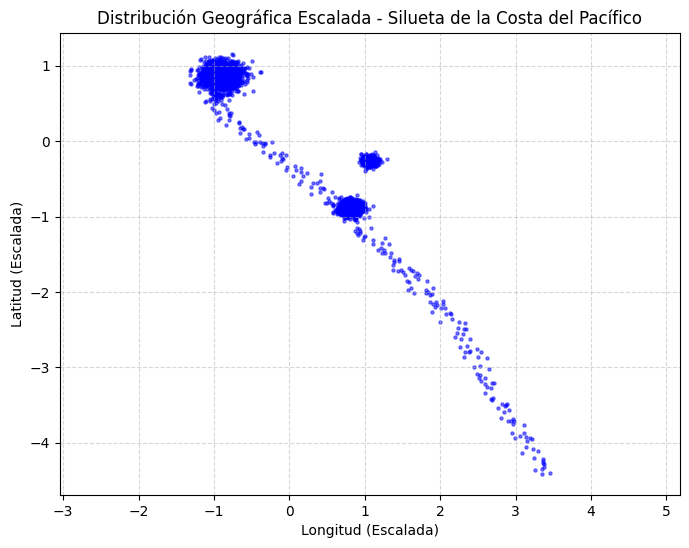

In [ ]:
# Fase 1 
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('logistica_baja_california.csv')

X_columnas = df[['Latitud', 'Longitud']]
st = StandardScaler()
X_scaled = st.fit_transform(X_columnas)

plt.figure(figsize=(8,6))
plt.scatter(X_scaled[:, 1], X_scaled[:, 0], color='blue', alpha=0.5, s=5)
plt.title('Distribución Geográfica Escalada - Silueta de la Costa del Pacífico')
plt.xlabel('Longitud (Escalada)')
plt.ylabel('Latitud (Escalada)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal') 
plt.show()

c:\Users\dael0\miniconda3\envs\mineria_datos\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=13.
  warnings.warn(


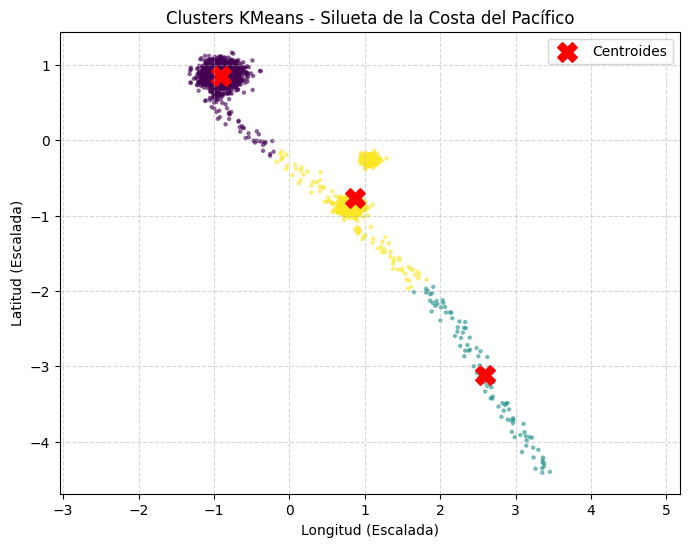

In [ ]:
#Fase 2 k means
from sklearn.cluster import KMeans
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(X_scaled)
labels = kmeans.labels_

plt.figure(figsize=(8,6))
plt.scatter(X_scaled[:, 1], X_scaled[:, 0], c=labels, cmap='viridis', alpha=0.5, s=5)
plt.title('Clusters KMeans - Silueta de la Costa del Pacífico')
plt.xlabel('Longitud (Escalada)')
plt.ylabel('Latitud (Escalada)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 1], centers[:, 0], c='red', marker='X', s=200, label='Centroides')
plt.legend()
plt.show()


¿Dónde colocó el algoritmo que seleccionaron las Cedis? ¿Consideran que sus localizaciones hacen sentido?
El algoritmo identificó las ubicaciones potenciales de los Cedis en donde se concentra la mayor población de los tres agrupamientos, las localizaciones sí hacen sentido porque quedan en el centro donde se ve que hay mayor demanda, por ende, se minimizan los kilometros de viaje a los clientes potenciales.

¿Por qué la matemática de este algoritmo provocó esto?
Como seleccionamos que fueran 3 grupos para obtener zonas estratégicas para los CEDIS, el algoritmo lo que hizo fue, a partir de las distancias, asigno cada punto al grupo que mas se le acercara y calculó el punto central (centroide) de cada grupo para ubicar ahí el CEDIS, garantizando así que la distancia total de reparto sea la menor posible.

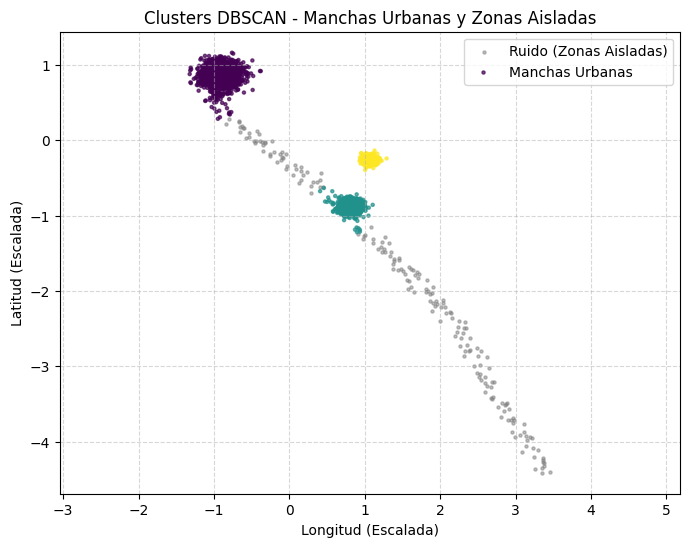

In [ ]:
#Fase 3 DBSCAN
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.15, min_samples=15)
dbscan_labels = dbscan.fit_predict(X_scaled)
plt.figure(figsize=(8,6))
ruido = (dbscan_labels == -1)
plt.scatter(X_scaled[ruido, 1], X_scaled[ruido, 0], color='gray', alpha=0.5, s=5, label='Ruido (Zonas Aisladas)')

validos = (dbscan_labels != -1)
plt.scatter(X_scaled[validos, 1], X_scaled[validos, 0], c=dbscan_labels[validos], cmap='viridis', alpha=0.7, s=5, label='Manchas Urbanas')

plt.title('Clusters DBSCAN - Manchas Urbanas y Zonas Aisladas')
plt.xlabel('Longitud (Escalada)')
plt.ylabel('Latitud (Escalada)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')
plt.legend()
plt.show()

¿Usaron el mismo algoritmo que en la misión anterior?
No, usamos un algoritmo que se adecúa mas a esta situación específica donde tenemos que eliminar a los outliers o el ruido innecesario.

¿De no ser así, porqué se comportaron diferentes?
En kmeans todos los puntos si o si pertenecen a un cluster que se calcula dependiendo de la distancia de un centroide, mientras que dbscan se basa mas que nada en la densidad, si los puntos estan muy lejos de esa densidad (cluster-1), lo clasifica como ruido.

¿A qué ciudades reales corresponden las 3 manchas urbanas que encontró su algoritmo?
Estas manchas pertenen a Tijuana, Valle de Guadalupe y Ensenada.